# FS-Swin-Unet: Fully supervised Swin-Unet for blood cell segmentation

**Swin-Unet**: Transformer (~27M parameters, initialized from ImageNet Swin-T) – the "teacher" in DACL.

This notebook is **self-contained** (no repository cloning needed):
1. Experiment configuration
2. Data preparation & splitting
3. **Data augmentation** – configuration + visual preview
4. Dataset / DataLoader
5. Swin-Unet model
6. Loss & evaluation metrics
7. Training loop
8. Experiments at each label ratio
9. Results: table, training curves, prediction overlays

## 1. Experiment configuration

In [1]:
# ================================================================
#                    EXPERIMENT CONFIGURATION
#  Edit this cell only. All cells below read their settings from CFG.
# ================================================================
class CFG:
    # ---------------- PATHS ----------------
    # RAW dataset folder on Kaggle ("Input" panel on the right -> copy path button).
    # Expected layout:
    #   bloodcell_dataset/
    #     ├── Original/   microscopy images
    #     └── Mask/       ground-truth masks (paired with images by file name)
    # If this path does not exist, the folder holding Original/ + Mask/ is searched
    # automatically under /kaggle/input.
    RAW_DIR = "/kaggle/input/bloodcell/bloodcell_dataset"
    IMAGE_SUBDIR = "Original"
    MASK_SUBDIR = "Mask"
    # Where prepared data and results are written. On Kaggle only /kaggle/working is kept.
    WORK_DIR = "/kaggle/working"

    # ---------------- MODEL ----------------
    MODEL = "swin_unet"
    NUM_CLASSES = 2          # 0 = background, 1 = cell (binary masks)
    # Initial weights:
    #   "imagenet"   -> download Microsoft's Swin-T (ImageNet-1K) - Internet must be ON
    #   "/kaggle/input/.../swin_tiny_patch4_window7_224.pth" -> uploaded file (Internet OFF)
    #   ""           -> random init (not recommended; DACL uses the pretrained model)
    PRETRAINED = "imagenet"
    # Stochastic depth: randomly drops Transformer blocks during training -> less overfitting.
    # 0.1 as in the original Swin-Unet; consider 0.2 with only 5% labels.
    DROP_PATH = 0.1

    # ---------------- DATA ----------------
    # The 1600x1200 originals are resized ONCE to this size (keeps the 4:3 ratio), so the
    # DataLoader never decodes large images during training -> much faster.
    PREP_SIZE = (640, 480)   # (width, height)
    # Masks are stored as JPG (compression noise) -> pixels > threshold are cell.
    MASK_THRESHOLD = 127
    # Network input size. 224 matches Swin-Unet (window 7, ImageNet weights at 224).
    # KEEP 224 for both UNeXt and Swin-Unet for a fair comparison.
    IMG_SIZE = 224
    # Train/val/test ratios and split seed. KEEP the same seed across notebooks so every
    # model (FS, DACL, baselines) uses the SAME data split.
    SPLIT_RATIOS = (0.7, 0.1, 0.2)
    SPLIT_SEED = 2026
    # Label ratios (%) to run. 100 = the whole training set (upper bound).
    # 5/10/20 = only the labeled part of the SSL experiments (SSL lower bound).
    LABELED_RATIOS = [5, 10, 20, 100]

    # ---------------- TRAINING ----------------
    # Train for a fixed NUMBER OF ITERATIONS (not epochs): same number of updates at every ratio.
    MAX_ITERS = 30000
    # Batch size. Swin-Unet (~27M params): 8 fits a 16GB GPU with AMP.
    # On "CUDA out of memory" -> reduce to 4.
    BATCH_SIZE = 8
    # SGD as in the DACL paper; poly learning-rate decay: lr*(1 - it/max_it)^0.9.
    BASE_LR = 0.01
    MOMENTUM = 0.9
    WEIGHT_DECAY = 1e-4
    # FP16 mixed precision: ~1.5-2x faster and less GPU memory.
    USE_AMP = True
    # Data-loading workers (Kaggle has 4 CPUs).
    NUM_WORKERS = 4
    # Seeds. Add 2027, 2028 to repeat runs and report mean ± std.
    SEEDS = [2026]

    # ---------------- EVALUATION & LOGGING ----------------
    # Validate every VAL_INTERVAL iterations; save best.pth when the Dice improves.
    VAL_INTERVAL = 500
    LOG_INTERVAL = 100

    # ---------------- DRY RUN ----------------
    # True -> each experiment runs only 300 iterations, to test the whole notebook in minutes.
    # REMEMBER to set it back to False for the real run.
    DEBUG = False


if CFG.DEBUG:
    CFG.MAX_ITERS, CFG.VAL_INTERVAL, CFG.LOG_INTERVAL = 300, 100, 50

In [2]:
import csv, json, os, random, re, shutil, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import albumentations as A
from albumentations.pytorch import ToTensorV2
from scipy import ndimage
from skimage.color import hed2rgb, rgb2hed
from timm.layers import DropPath, to_2tuple, trunc_normal_
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path(CFG.WORK_DIR) / "data" / "processed"
SPLIT_DIR = Path(CFG.WORK_DIR) / "data" / "splits"
RUN_ROOT = Path(CFG.WORK_DIR) / "runs"
print("torch", torch.__version__, "| albumentations", A.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | albumentations 2.0.8 | device: cuda
GPU: Tesla T4


## 2. Data preparation & splitting

- Pair `Original/<name>` with `Mask/<name>` by file name (extension and suffixes such as `_mask` are ignored), resize, binarize masks.
- **70/10/20** split (train/val/test) with a fixed seed; the first **2/5/10/20%** of train are the labeled subsets.
- This cell **skips itself** if the data was already prepared in the current session.

> Check the log: **1328 pairs** must be found, and the cell-pixel ratio must not be close to 0 or 1.

In [3]:
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
# Suffixes ignored when matching names, e.g. "12_mask.png" in Mask/ pairs with "12.jpg" in Original/.
SUFFIX_RE = re.compile(r"[ _\-]?(mask|masks|gt|label|labels|image|images|img|original)$", re.I)


def find_raw_dir():
    """Return the folder containing IMAGE_SUBDIR and MASK_SUBDIR."""
    root = Path(CFG.RAW_DIR)
    if (root / CFG.IMAGE_SUBDIR).is_dir() and (root / CFG.MASK_SUBDIR).is_dir():
        return root
    for cand in Path("/kaggle/input").rglob(CFG.MASK_SUBDIR):
        if cand.is_dir() and (cand.parent / CFG.IMAGE_SUBDIR).is_dir():
            print(f"CFG.RAW_DIR not found - using {cand.parent}")
            return cand.parent
    raise FileNotFoundError(f"No folder with {CFG.IMAGE_SUBDIR}/ and {CFG.MASK_SUBDIR}/ found - check CFG.RAW_DIR.")


def _index(folder):
    files = sorted(p for p in folder.rglob("*") if p.suffix.lower() in EXTS)
    return {SUFFIX_RE.sub("", p.stem).strip().lower(): p for p in files}


def prepare_dataset():
    if (DATA_DIR / "DONE").exists():
        print("Data already prepared - skipping.")
        return
    raw = find_raw_dir()
    images, masks = _index(raw / CFG.IMAGE_SUBDIR), _index(raw / CFG.MASK_SUBDIR)
    keys = sorted(set(images) & set(masks))
    print(f"Found {len(images)} images, {len(masks)} masks -> {len(keys)} pairs")
    if len(keys) < max(len(images), len(masks)):
        print("  unmatched images (examples):", [images[k].name for k in sorted(set(images) - set(masks))[:5]])
        print("  unmatched masks  (examples):", [masks[k].name for k in sorted(set(masks) - set(images))[:5]])
    if not keys:
        raise RuntimeError("No image/mask pairs found - the file names in the two folders do not match.")
    for k in keys[:3]:
        print(f"  pair: {images[k].name}  <->  {masks[k].name}")
    (DATA_DIR / "images").mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "masks").mkdir(parents=True, exist_ok=True)
    fg = []
    for i, k in enumerate(tqdm(keys, desc="Preparing")):
        img = cv2.imread(str(images[k]), cv2.IMREAD_COLOR)
        msk = cv2.imread(str(masks[k]), cv2.IMREAD_GRAYSCALE)
        if img is None or msk is None:
            print("  skipping unreadable file:", k)
            continue
        img = cv2.resize(img, CFG.PREP_SIZE, interpolation=cv2.INTER_AREA)
        msk = cv2.resize(msk, CFG.PREP_SIZE, interpolation=cv2.INTER_NEAREST)
        msk = np.where(msk > CFG.MASK_THRESHOLD, 255, 0).astype(np.uint8)
        cv2.imwrite(str(DATA_DIR / "images" / f"{i:04d}.png"), img)
        cv2.imwrite(str(DATA_DIR / "masks" / f"{i:04d}.png"), msk)
        fg.append((msk > 0).mean())
    (DATA_DIR / "DONE").write_text("ok")
    print(f"Saved {len(fg)} pairs | mean cell-pixel ratio: {np.mean(fg):.3f}")


def split_dataset():
    names = sorted(p.stem for p in (DATA_DIR / "images").glob("*.png"))
    random.Random(CFG.SPLIT_SEED).shuffle(names)
    n = len(names)
    n_tr, n_va = round(CFG.SPLIT_RATIOS[0] * n), round(CFG.SPLIT_RATIOS[1] * n)
    split = {"train": names[:n_tr], "val": names[n_tr:n_tr + n_va], "test": names[n_tr + n_va:]}
    for pct in (2, 5, 10, 20):  # 2% for the extreme low-label experiment
        split[f"labeled_{pct}"] = split["train"][:int(len(split["train"]) * pct / 100)]
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    for k, v in split.items():
        (SPLIT_DIR / f"{k}.txt").write_text("\n".join(v) + "\n", encoding="utf-8")
    print({k: len(v) for k, v in split.items()})
    return split


prepare_dataset()
SPLIT = split_dataset()

CFG.RAW_DIR not found - using /kaggle/input/datasets/duybnh/bloodcell/bloodcell_dataset
Found 1328 images, 1328 masks -> 1328 pairs
  pair: 002f20ad-2ace-499c-9335-c9080bc3e6b5.png  <->  002f20ad-2ace-499c-9335-c9080bc3e6b5.png
  pair: 003a89b0-a095-417a-8dd6-f408339bbc68.png  <->  003a89b0-a095-417a-8dd6-f408339bbc68.png
  pair: 003d1cdc-0aec-430b-90e0-f4d82135b1ac.png  <->  003d1cdc-0aec-430b-90e0-f4d82135b1ac.png


Preparing:   0%|          | 0/1328 [00:00<?, ?it/s]

Saved 1328 pairs | mean cell-pixel ratio: 0.294
{'train': 930, 'val': 133, 'test': 265, 'labeled_2': 18, 'labeled_5': 46, 'labeled_10': 93, 'labeled_20': 186}


## 3. Data augmentation

Applied to **labeled training images only**; validation/test are only resized + normalized.
Augmentation is **online**: every time an image is loaded a new random variant is generated, so over
30k iterations the model practically never sees the same image twice – no need to write extra
augmented images to disk (offline augmentation).

| Group | Transform | What it simulates |
|---|---|---|
| Geometric | Horizontal/vertical flip, 90° rotation | Cells have no canonical orientation |
| | Affine (scale, small rotation, translation) | Different magnification and slide placement |
| | Elastic | Slight cell-shape deformation |
| Color / stain | Color jitter | Different lamps, cameras, white balance |
| | **HED stain jitter** | Stronger/weaker staining between slides and labs |
| | Gamma, CLAHE | Different contrast and exposure |
| Image quality | Gaussian blur, Gaussian noise | Imperfect focus, sensor noise |

**`LEVEL`** – use it for an augmentation ablation:
- `"none"`: no augmentation · `"basic"`: geometric only · `"full"`: geometric + color/stain + image quality

In [4]:
# ================================================================
#                DATA AUGMENTATION CONFIGURATION
#  p = probability of applying each transform to an image (0 = off, 1 = always)
# ================================================================
class AUG:
    LEVEL = "full"            # "none" | "basic" | "full"

    # ---- Geometric (applied to the image AND the mask) ----
    HFLIP_P = 0.5             # horizontal flip
    VFLIP_P = 0.5             # vertical flip
    ROT90_P = 0.5             # rotate by 90/180/270 degrees
    AFFINE_P = 0.5            # affine transform:
    SCALE = (0.85, 1.15)      #   scale 0.85-1.15x (magnification differences)
    ROTATE = (-15, 15)        #   extra rotation ±15 degrees
    TRANSLATE = (-0.05, 0.05) #   shift ±5% of the image size
    ELASTIC_P = 0.2           # elastic deformation
    ELASTIC_ALPHA = 30        #   strength (too large distorts cell shapes unrealistically)
    ELASTIC_SIGMA = 6         #   smoothness of the displacement field

    # ---- Color / stain (image ONLY, the mask is unchanged) ----
    COLOR_JITTER_P = 0.5
    BRIGHTNESS = 0.2          # brightness ±20%
    CONTRAST = 0.2            # contrast ±20%
    SATURATION = 0.2          # saturation ±20%
    HUE = 0.05                # hue ±0.05 (kept small so cell colors stay plausible)
    HED_P = 0.5               # stain jitter in HED color space (Hematoxylin-Eosin-DAB):
    HED_SIGMA = 0.05          #   per-channel multiplicative factor ~ U(1-σ, 1+σ)
    HED_BIAS = 0.005          #   per-channel additive shift ~ U(-b, b). skimage HED values lie in
                              #   ~[0, 0.1], so b must be SMALL; b = 0.02 already whitened the background.
                              #   (Blood smears use Giemsa/Wright stain; HED is a reasonable
                              #    approximation of the purple/pink dyes and standard in histopathology.)
    GAMMA_P = 0.2
    GAMMA = (80, 120)         # gamma 0.8-1.2 (in %)
    CLAHE_P = 0.1             # contrast-limited adaptive histogram equalization

    # ---- Image quality ----
    BLUR_P = 0.1              # Gaussian blur (defocus)
    NOISE_P = 0.1             # Gaussian noise (sensor noise)
    NOISE_STD = (0.01, 0.04)  #   noise std on a [0, 1] scale (0.04 ≈ ±10 grey levels)

    # ---- Normalization ----
    # ImageNet statistics: required by the pretrained Swin-Unet; shared with UNeXt so
    # both models receive identical inputs.
    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)

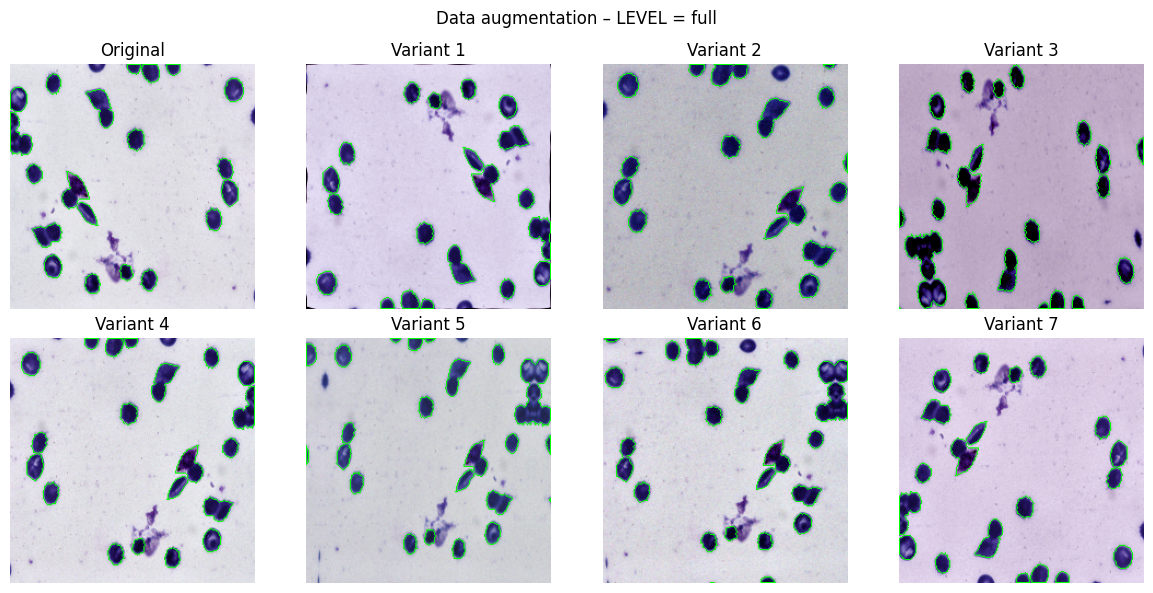

In [5]:
# albumentations 1.x and 2.x use different argument names -> two helpers support both.
ALB_V2 = int(A.__version__.split(".")[0]) >= 2


def _affine():
    # Empty areas created by rotation/scaling are filled by reflection (no artificial black borders).
    border = {"border_mode": cv2.BORDER_REFLECT_101} if ALB_V2 else {"mode": cv2.BORDER_REFLECT_101}
    return A.Affine(scale=AUG.SCALE, rotate=AUG.ROTATE, translate_percent=AUG.TRANSLATE,
                    p=AUG.AFFINE_P, **border)


def _noise():
    if ALB_V2:
        return A.GaussNoise(std_range=AUG.NOISE_STD, p=AUG.NOISE_P)
    var = tuple((s * 255) ** 2 for s in AUG.NOISE_STD)  # 1.x uses variance on a 0-255 scale
    return A.GaussNoise(var_limit=var, p=AUG.NOISE_P)


def hed_jitter(img, **kwargs):
    """HED stain jitter (Tellez et al., 2018): RGB -> HED, perturb each channel, back to RGB."""
    hed = rgb2hed(img.astype(np.float32) / 255.0)
    alpha = np.random.uniform(1 - AUG.HED_SIGMA, 1 + AUG.HED_SIGMA, 3)
    beta = np.random.uniform(-AUG.HED_BIAS, AUG.HED_BIAS, 3)
    rgb = hed2rgb(hed * alpha + beta)
    return (np.clip(rgb, 0, 1) * 255).astype(np.uint8)


def build_train_transform(level=None, normalize=True):
    level = level or AUG.LEVEL
    t = [A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE)]
    if level in ("basic", "full"):
        t += [
            A.HorizontalFlip(p=AUG.HFLIP_P),
            A.VerticalFlip(p=AUG.VFLIP_P),
            A.RandomRotate90(p=AUG.ROT90_P),
            _affine(),
            A.ElasticTransform(alpha=AUG.ELASTIC_ALPHA, sigma=AUG.ELASTIC_SIGMA, p=AUG.ELASTIC_P),
        ]
    if level == "full":
        t += [
            A.ColorJitter(brightness=AUG.BRIGHTNESS, contrast=AUG.CONTRAST,
                          saturation=AUG.SATURATION, hue=AUG.HUE, p=AUG.COLOR_JITTER_P),
            A.Lambda(image=hed_jitter, p=AUG.HED_P),
            A.RandomGamma(gamma_limit=AUG.GAMMA, p=AUG.GAMMA_P),
            A.CLAHE(p=AUG.CLAHE_P),
            A.GaussianBlur(blur_limit=(3, 5), p=AUG.BLUR_P),
            _noise(),
        ]
    if normalize:
        t += [A.Normalize(mean=AUG.MEAN, std=AUG.STD), ToTensorV2()]
    return A.Compose(t)


def build_eval_transform():
    return A.Compose([A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE),
                      A.Normalize(mean=AUG.MEAN, std=AUG.STD), ToTensorV2()])


def show_augmentations(name=None, n=7, level=None):
    """Show the original + n augmented variants; green contour = transformed mask."""
    name = name or SPLIT["train"][0]
    img = cv2.cvtColor(cv2.imread(str(DATA_DIR / "images" / f"{name}.png")), cv2.COLOR_BGR2RGB)
    msk = (cv2.imread(str(DATA_DIR / "masks" / f"{name}.png"), 0) > 127).astype(np.uint8)
    tf = build_train_transform(level, normalize=False)
    base = A.Compose([A.Resize(CFG.IMG_SIZE, CFG.IMG_SIZE)])(image=img, mask=msk)
    samples = [("Original", base["image"], base["mask"])]
    for i in range(n):
        o = tf(image=img, mask=msk)
        samples.append((f"Variant {i + 1}", o["image"], o["mask"]))
    fig, axes = plt.subplots(2, (n + 2) // 2, figsize=(3 * ((n + 2) // 2), 6))
    for ax, (title, im, m) in zip(axes.ravel(), samples):
        vis = im.copy()
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cnts, -1, (0, 255, 0), 1)
        ax.imshow(vis); ax.set_title(title); ax.axis("off")
    plt.suptitle(f"Data augmentation – LEVEL = {level or AUG.LEVEL}")
    plt.tight_layout(); plt.show()


show_augmentations()

Compare the levels (re-run the cell to see other random variants):

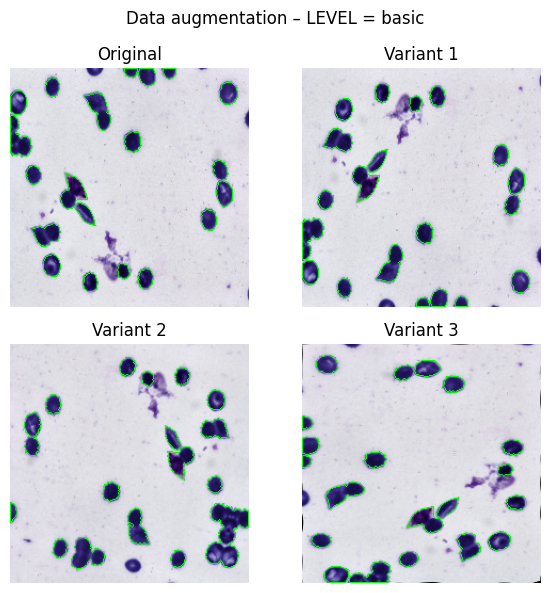

In [6]:
show_augmentations(level="basic", n=3)

## 4. Dataset / DataLoader

In [7]:
class BloodCellDataset(Dataset):
    def __init__(self, names, transform):
        self.names, self.transform = list(names), transform

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        name = self.names[i]
        img = cv2.cvtColor(cv2.imread(str(DATA_DIR / "images" / f"{name}.png")), cv2.COLOR_BGR2RGB)
        msk = (cv2.imread(str(DATA_DIR / "masks" / f"{name}.png"), 0) > 127).astype(np.uint8)
        o = self.transform(image=img, mask=msk)
        return {"image": o["image"], "mask": torch.as_tensor(o["mask"]).long(), "name": name}


def infinite_loader(loader):
    """Iterate a DataLoader forever (iteration-based training)."""
    while True:
        for b in loader:
            yield b

## 5. Swin-Unet model

U-Net-shaped pure Transformer (Cao et al., ECCV-W 2022). ImageNet Swin-T weights are loaded into the encoder and mirrored into the decoder.

In [8]:
"""Swin-Unet: Unet-like Pure Transformer for Medical Image Segmentation (Cao et al., ECCV-W 2022).

Re-implemented from the official repo (HuCaoFighting/Swin-Unet), keeping parameter names so
Microsoft's ImageNet-pretrained Swin-T weights load directly.

"Tiny" configuration used in DACL:
  embed_dim=96, depths=[2,2,2,2], num_heads=[3,6,12,24], window_size=7, 224x224 input
  -> encoder features [96, 192, 384], bottleneck 768, ~27M parameters.
"""

# Official Microsoft Swin-T (ImageNet-1K) weights - the same file the Swin-Unet repo uses.
SWIN_TINY_URL = (
    "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/"
    "swin_tiny_patch4_window7_224.pth"
)


class Mlp(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, drop=0.0):
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, out_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(self.act(self.fc1(x)))))


def window_partition(x, ws):
    B, H, W, C = x.shape
    x = x.view(B, H // ws, ws, W // ws, ws, C)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(-1, ws, ws, C)


def window_reverse(windows, ws, H, W):
    B = int(windows.shape[0] / (H * W / ws / ws))
    x = windows.view(B, H // ws, W // ws, ws, ws, -1)
    return x.permute(0, 1, 3, 2, 4, 5).contiguous().view(B, H, W, -1)


class WindowAttention(nn.Module):
    """Local-window self-attention with relative position bias."""

    def __init__(self, dim, window_size, num_heads, qkv_bias=True, attn_drop=0.0, proj_drop=0.0):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size[0] - 1) * (2 * window_size[1] - 1), num_heads))
        coords = torch.stack(torch.meshgrid(
            torch.arange(window_size[0]), torch.arange(window_size[1]), indexing="ij"))
        coords = torch.flatten(coords, 1)
        rel = (coords[:, :, None] - coords[:, None, :]).permute(1, 2, 0).contiguous()
        rel[:, :, 0] += window_size[0] - 1
        rel[:, :, 1] += window_size[1] - 1
        rel[:, :, 0] *= 2 * window_size[1] - 1
        self.register_buffer("relative_position_index", rel.sum(-1))
        self.qkv = nn.Linear(dim, dim * 3, bias=qkv_bias)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)
        trunc_normal_(self.relative_position_bias_table, std=0.02)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, x, mask=None):
        B_, N, C = x.shape
        qkv = self.qkv(x).reshape(B_, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q * self.scale) @ k.transpose(-2, -1)
        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(N, N, -1)
        attn = attn + bias.permute(2, 0, 1).contiguous().unsqueeze(0)
        if mask is not None:
            nW = mask.shape[0]
            attn = attn.view(B_ // nW, nW, self.num_heads, N, N) + mask.unsqueeze(1).unsqueeze(0)
            attn = attn.view(-1, self.num_heads, N, N)
        attn = self.attn_drop(self.softmax(attn))
        x = (attn @ v).transpose(1, 2).reshape(B_, N, C)
        return self.proj_drop(self.proj(x))


class SwinTransformerBlock(nn.Module):
    def __init__(self, dim, input_resolution, num_heads, window_size=7, shift_size=0,
                 mlp_ratio=4.0, qkv_bias=True, drop=0.0, attn_drop=0.0, drop_path=0.0):
        super().__init__()
        self.dim = dim
        self.input_resolution = input_resolution
        self.window_size = window_size
        self.shift_size = shift_size
        if min(input_resolution) <= window_size:
            # Feature map not larger than the window -> no partitioning, no shift.
            self.shift_size = 0
            self.window_size = min(input_resolution)
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, to_2tuple(self.window_size), num_heads, qkv_bias, attn_drop, drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = Mlp(dim, int(dim * mlp_ratio), drop=drop)

        if self.shift_size > 0:
            H, W = input_resolution
            img_mask = torch.zeros((1, H, W, 1))
            cnt = 0
            for h in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size),
                      slice(-self.shift_size, None)):
                for w in (slice(0, -self.window_size), slice(-self.window_size, -self.shift_size),
                          slice(-self.shift_size, None)):
                    img_mask[:, h, w, :] = cnt
                    cnt += 1
            mw = window_partition(img_mask, self.window_size).view(-1, self.window_size ** 2)
            attn_mask = mw.unsqueeze(1) - mw.unsqueeze(2)
            attn_mask = attn_mask.masked_fill(attn_mask != 0, -100.0).masked_fill(attn_mask == 0, 0.0)
        else:
            attn_mask = None
        self.register_buffer("attn_mask", attn_mask)

    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        shortcut = x
        x = self.norm1(x).view(B, H, W, C)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        xw = window_partition(x, self.window_size).view(-1, self.window_size ** 2, C)
        aw = self.attn(xw, mask=self.attn_mask).view(-1, self.window_size, self.window_size, C)
        x = window_reverse(aw, self.window_size, H, W)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        x = shortcut + self.drop_path(x.view(B, H * W, C))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class PatchMerging(nn.Module):
    """Halve the resolution, double the channels (encoder)."""

    def __init__(self, input_resolution, dim):
        super().__init__()
        self.input_resolution = input_resolution
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)
        self.norm = nn.LayerNorm(4 * dim)

    def forward(self, x):
        H, W = self.input_resolution
        B, L, C = x.shape
        x = x.view(B, H, W, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], -1)
        return self.reduction(self.norm(x.view(B, -1, 4 * C)))


class PatchExpand(nn.Module):
    """Double the resolution, halve the channels (decoder)."""

    def __init__(self, input_resolution, dim, dim_scale=2):
        super().__init__()
        self.input_resolution = input_resolution
        self.expand = nn.Linear(dim, 2 * dim, bias=False) if dim_scale == 2 else nn.Identity()
        self.norm = nn.LayerNorm(dim // dim_scale)

    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        x = x.view(B, H, W, 2, 2, C // 4).permute(0, 1, 3, 2, 4, 5).reshape(B, H * 2 * W * 2, C // 4)
        return self.norm(x)


class FinalPatchExpandX4(nn.Module):
    """4x upsampling back to the input resolution."""

    def __init__(self, input_resolution, dim):
        super().__init__()
        self.input_resolution = input_resolution
        self.dim = dim
        self.expand = nn.Linear(dim, 16 * dim, bias=False)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        H, W = self.input_resolution
        x = self.expand(x)
        B, L, C = x.shape
        c = C // 16
        x = x.view(B, H, W, 4, 4, c).permute(0, 1, 3, 2, 4, 5).reshape(B, H * 4 * W * 4, c)
        return self.norm(x)


class BasicLayer(nn.Module):
    def __init__(self, dim, input_resolution, depth, num_heads, window_size, mlp_ratio, qkv_bias,
                 drop, attn_drop, drop_path, downsample=None, upsample=None):
        super().__init__()
        self.blocks = nn.ModuleList([
            SwinTransformerBlock(dim, input_resolution, num_heads, window_size,
                                 0 if i % 2 == 0 else window_size // 2,  # even blocks: W-MSA, odd: SW-MSA
                                 mlp_ratio, qkv_bias, drop, attn_drop,
                                 drop_path[i] if isinstance(drop_path, list) else drop_path)
            for i in range(depth)])
        self.downsample = downsample(input_resolution, dim) if downsample is not None else None
        self.upsample = upsample(input_resolution, dim, 2) if upsample is not None else None

    def forward(self, x):
        for blk in self.blocks:
            x = blk(x)
        if self.downsample is not None:
            x = self.downsample(x)
        if self.upsample is not None:
            x = self.upsample(x)
        return x


class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=4, in_chans=3, embed_dim=96):
        super().__init__()
        self.patches_resolution = [img_size // patch_size, img_size // patch_size]
        self.proj = nn.Conv2d(in_chans, embed_dim, patch_size, patch_size)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        return self.norm(self.proj(x).flatten(2).transpose(1, 2))


class SwinUnet(nn.Module):
    def __init__(self, img_size=224, num_classes=2, in_chans=3, embed_dim=96,
                 depths=(2, 2, 2, 2), num_heads=(3, 6, 12, 24), window_size=7,
                 mlp_ratio=4.0, qkv_bias=True, drop_rate=0.0, attn_drop_rate=0.0, drop_path_rate=0.1):
        """
        img_size: input size. img_size/4, /8, /16 must be divisible by window_size
                  -> with window 7 use 224 (or 448).
        drop_path_rate: stochastic depth against overfitting (0.1 in the original Swin-Unet config).
        """
        super().__init__()
        self.num_layers = len(depths)
        self.patch_embed = PatchEmbed(img_size, 4, in_chans, embed_dim)
        pr = self.patch_embed.patches_resolution
        self.pos_drop = nn.Dropout(drop_rate)
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, sum(depths))]
        L = self.num_layers

        # ---- Encoder ----
        self.layers = nn.ModuleList()
        for i in range(L):
            self.layers.append(BasicLayer(
                int(embed_dim * 2 ** i), (pr[0] // 2 ** i, pr[1] // 2 ** i), depths[i], num_heads[i],
                window_size, mlp_ratio, qkv_bias, drop_rate, attn_drop_rate,
                dpr[sum(depths[:i]):sum(depths[:i + 1])],
                downsample=PatchMerging if i < L - 1 else None))

        # ---- Decoder (symmetric) ----
        self.layers_up = nn.ModuleList()
        self.concat_back_dim = nn.ModuleList()
        for i in range(L):
            j = L - 1 - i
            dim = int(embed_dim * 2 ** j)
            res = (pr[0] // 2 ** j, pr[1] // 2 ** j)
            self.concat_back_dim.append(nn.Linear(2 * dim, dim) if i > 0 else nn.Identity())
            if i == 0:
                self.layers_up.append(PatchExpand(res, dim, 2))
            else:
                self.layers_up.append(BasicLayer(
                    dim, res, depths[j], num_heads[j], window_size, mlp_ratio, qkv_bias,
                    drop_rate, attn_drop_rate, dpr[sum(depths[:j]):sum(depths[:j + 1])],
                    upsample=PatchExpand if i < L - 1 else None))

        self.norm = nn.LayerNorm(int(embed_dim * 2 ** (L - 1)))
        self.norm_up = nn.LayerNorm(embed_dim)
        self.up = FinalPatchExpandX4((img_size // 4, img_size // 4), embed_dim)
        self.output = nn.Conv2d(embed_dim, num_classes, 1, bias=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        B = x.shape[0]
        x = self.pos_drop(self.patch_embed(x))
        skips = []
        for layer in self.layers:
            skips.append(x)
            x = layer(x)
        x = self.norm(x)
        for i, layer_up in enumerate(self.layers_up):
            if i > 0:
                x = self.concat_back_dim[i](torch.cat([x, skips[self.num_layers - 1 - i]], -1))
            x = layer_up(x)
        x = self.up(self.norm_up(x))
        H, W = self.up.input_resolution
        x = x.view(B, 4 * H, 4 * W, -1).permute(0, 3, 1, 2)
        return self.output(x)  # logits (B, num_classes, H, W)

    def load_pretrained(self, path_or_url=SWIN_TINY_URL):
        """Load ImageNet Swin-T weights into the encoder AND mirror them into the decoder
        (layers.k -> layers_up.(3-k)), as the original Swin-Unet does. Shape-mismatched keys are skipped."""
        if str(path_or_url).startswith("http"):
            ckpt = torch.hub.load_state_dict_from_url(path_or_url, map_location="cpu", progress=True)
        else:
            ckpt = torch.load(path_or_url, map_location="cpu")
        pre = ckpt.get("model", ckpt)
        pre = {k: v for k, v in pre.items() if not k.startswith("head")}
        full = dict(pre)
        for k, v in pre.items():
            if k.startswith("layers."):
                full["layers_up." + str(3 - int(k[7])) + k[8:]] = v
        own = self.state_dict()
        loadable = {k: v for k, v in full.items() if k in own and own[k].shape == v.shape}
        self.load_state_dict(loadable, strict=False)
        print(f"[Swin-Unet] loaded {len(loadable)}/{len(own)} tensors from pretrained weights")
        return len(loadable)

In [9]:
def build_model(pretrained=True):
    """pretrained=False when only the architecture is needed to load best.pth."""
    model = SwinUnet(img_size=CFG.IMG_SIZE, num_classes=CFG.NUM_CLASSES, drop_path_rate=CFG.DROP_PATH)
    if pretrained and CFG.PRETRAINED:
        model.load_pretrained(SWIN_TINY_URL if CFG.PRETRAINED == "imagenet" else CFG.PRETRAINED)
    return model


_m = build_model(pretrained=False)
print(f"Swin-Unet: {sum(p.numel() for p in _m.parameters()) / 1e6:.2f}M params")
print("Output:", tuple(_m(torch.randn(1, 3, CFG.IMG_SIZE, CFG.IMG_SIZE)).shape))
del _m

Swin-Unet: 27.17M params
Output: (1, 2, 224, 224)


## 6. Loss & evaluation metrics

In [10]:
class DiceLoss(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.n = n_classes

    def forward(self, logits, target):
        prob = torch.softmax(logits, 1)
        oh = F.one_hot(target, self.n).permute(0, 3, 1, 2).float()
        inter = (prob * oh).sum((0, 2, 3))
        union = prob.sum((0, 2, 3)) + oh.sum((0, 2, 3))
        return 1 - ((2 * inter + 1e-5) / (union + 1e-5)).mean()


DICE = DiceLoss(CFG.NUM_CLASSES)


def sup_loss(logits, target):
    """L_sup = Cross-Entropy + Dice (as in DACL)."""
    return F.cross_entropy(logits, target) + DICE(logits, target)


def _surface(m):
    return m ^ ndimage.binary_erosion(m, structure=ndimage.generate_binary_structure(2, 1))


def binary_metrics(pred, gt):
    """DSC, Jaccard, HD95, ASD for binary masks. HD95/ASD in PIXELS at IMG_SIZE resolution."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    ps, gs = pred.sum(), gt.sum()
    if ps == 0 and gs == 0:
        return {"dsc": 1.0, "jaccard": 1.0, "hd95": 0.0, "asd": 0.0}
    inter = (pred & gt).sum()
    dsc, jac = 2 * inter / (ps + gs), inter / (pred | gt).sum()
    if ps == 0 or gs == 0:  # one side empty -> maximum distance penalty (image diagonal)
        d = float(np.hypot(*pred.shape))
        return {"dsc": float(dsc), "jaccard": float(jac), "hd95": d, "asd": d}
    sp, sg = _surface(pred), _surface(gt)
    d = np.concatenate([ndimage.distance_transform_edt(~sg)[sp], ndimage.distance_transform_edt(~sp)[sg]])
    return {"dsc": float(dsc), "jaccard": float(jac), "hd95": float(np.percentile(d, 95)), "asd": float(d.mean())}

## 7. Training loop

- Each experiment is saved to `runs/<model>_<ratio>p_s<seed>/`: `best.pth`, `last.pth`, `log.csv`, `config.json`, `test_per_image.csv`, `test_summary.json`.
- **Resumes automatically** from `last.pth` if an experiment is unfinished; **skips** experiments that already have `test_summary.json`.
- At the end of each experiment, `best.pth` (highest validation Dice) is loaded and evaluated on the test set.

In [11]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def evaluate(model, loader, full=False):
    model.eval()
    rows = []
    for b in loader:
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=CFG.USE_AMP and DEVICE.type == "cuda"):
            pred = model(b["image"].to(DEVICE)).argmax(1).cpu().numpy()
        for p, g, n in zip(pred, b["mask"].numpy(), b["name"]):
            if full:
                r = binary_metrics(p == 1, g == 1)
            else:
                s = (p == 1).sum() + (g == 1).sum()
                r = {"dsc": 1.0 if s == 0 else 2 * ((p == 1) & (g == 1)).sum() / s}
            r["name"] = n
            rows.append(r)
    model.train()
    return float(np.mean([r["dsc"] for r in rows])), rows


def run_test(model, out_dir):
    loader = DataLoader(BloodCellDataset(SPLIT["test"], build_eval_transform()), batch_size=8,
                        num_workers=CFG.NUM_WORKERS)
    _, rows = evaluate(model, loader, full=True)
    keys = ["dsc", "jaccard", "hd95", "asd"]
    pd.DataFrame(rows)[["name"] + keys].to_csv(out_dir / "test_per_image.csv", index=False)
    summary = {}
    for k in keys:
        v = np.array([r[k] for r in rows]) * (100 if k in ("dsc", "jaccard") else 1)  # DSC, Jaccard in %
        summary[k] = {"mean": float(v.mean()), "std": float(v.std())}
    (out_dir / "test_summary.json").write_text(json.dumps(summary, indent=2))
    return summary


def train_one(ratio, seed):
    out_dir = RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{seed}"
    if (out_dir / "test_summary.json").exists():
        print(f"== {out_dir.name}: already done, skipping ==")
        return json.loads((out_dir / "test_summary.json").read_text())
    out_dir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    cfg_dump = {k: v for k, v in vars(CFG).items() if k.isupper()}
    cfg_dump.update({"AUG_" + k: v for k, v in vars(AUG).items() if k.isupper()})
    cfg_dump.update(ratio=ratio, seed=seed)
    (out_dir / "config.json").write_text(json.dumps(cfg_dump, indent=2, default=str))

    names = SPLIT["train"] if ratio == 100 else SPLIT[f"labeled_{ratio}"]
    if not names:
        raise ValueError(f"No labeled images at {ratio}% - check LABELED_RATIOS / the data.")
    print(f"\n== {out_dir.name}: {len(names)} labeled images, {CFG.MAX_ITERS} iterations ==")
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(BloodCellDataset(names, build_train_transform()),
                              batch_size=min(CFG.BATCH_SIZE, len(names)), shuffle=True, drop_last=True,
                              num_workers=CFG.NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                              generator=g, persistent_workers=CFG.NUM_WORKERS > 0)
    val_loader = DataLoader(BloodCellDataset(SPLIT["val"], build_eval_transform()), batch_size=8,
                            num_workers=CFG.NUM_WORKERS)

    model = build_model().to(DEVICE)
    opt = torch.optim.SGD(model.parameters(), lr=CFG.BASE_LR, momentum=CFG.MOMENTUM,
                          weight_decay=CFG.WEIGHT_DECAY)
    use_amp = CFG.USE_AMP and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=use_amp)

    start, best = 0, -1.0
    if (out_dir / "last.pth").exists():
        ck = torch.load(out_dir / "last.pth", map_location=DEVICE)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start, best = ck["iter"], ck["best"]
        print(f"   resuming from iteration {start} (best val Dice {best:.4f})")
    log_f = open(out_dir / "log.csv", "a", newline="")
    log = csv.writer(log_f)
    if start == 0:
        log.writerow(["iter", "lr", "loss", "val_dice"])

    model.train()
    it_loader = infinite_loader(train_loader)
    running, t0 = 0.0, time.time()
    for it in range(start, CFG.MAX_ITERS):
        b = next(it_loader)
        img, msk = b["image"].to(DEVICE, non_blocking=True), b["mask"].to(DEVICE, non_blocking=True)
        lr = CFG.BASE_LR * (1 - it / CFG.MAX_ITERS) ** 0.9
        for pg in opt.param_groups:
            pg["lr"] = lr
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = model(img)
        loss = sup_loss(logits.float(), msk)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        running += loss.item()

        step = it + 1
        if step % CFG.LOG_INTERVAL == 0:
            print(f"   [{step:6d}/{CFG.MAX_ITERS}] loss {running / CFG.LOG_INTERVAL:.4f} | lr {lr:.5f} "
                  f"| {CFG.LOG_INTERVAL / (time.time() - t0):.1f} it/s")
            log.writerow([step, lr, running / CFG.LOG_INTERVAL, ""])
            running, t0 = 0.0, time.time()
        if step % CFG.VAL_INTERVAL == 0 or step == CFG.MAX_ITERS:
            vd, _ = evaluate(model, val_loader)
            log.writerow([step, "", "", vd]); log_f.flush()
            if vd > best:
                best = vd
                torch.save({"model": model.state_dict(), "iter": step, "val_dice": vd}, out_dir / "best.pth")
            print(f"   -> val Dice {vd:.4f} | best {best:.4f}")
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "iter": step, "best": best}, out_dir / "last.pth")
    log_f.close()

    model.load_state_dict(torch.load(out_dir / "best.pth", map_location=DEVICE)["model"])
    s = run_test(model, out_dir)
    print("   TEST:", "  ".join(f"{k.upper()} {v['mean']:.2f}({v['std']:.2f})" for k, v in s.items()))
    return s

## 8. Experiments at each label ratio

Rough estimate on a T4 GPU (not measured): UNeXt ~25-40 min / 30k iterations, Swin-Unet ~1.5-3 h / 30k iterations. If 12 h is not enough, split `LABELED_RATIOS` over several sessions.

In [12]:
results = []
for ratio in CFG.LABELED_RATIOS:
    for seed in CFG.SEEDS:
        s = train_one(ratio, seed)
        results.append({"model": CFG.MODEL, "labeled_%": ratio, "seed": seed,
                        **{f"{k}_mean": v["mean"] for k, v in s.items()},
                        **{f"{k}_std": v["std"] for k, v in s.items()}})


== swin_unet_5p_s2026: 46 labeled images, 30000 iterations ==
Downloading: "https://github.com/SwinTransformer/storage/releases/download/v1.0.0/swin_tiny_patch4_window7_224.pth" to /root/.cache/torch/hub/checkpoints/swin_tiny_patch4_window7_224.pth


100%|██████████| 109M/109M [00:00<00:00, 234MB/s]


[Swin-Unet] loaded 217/238 tensors from pretrained weights
   [   100/30000] loss 0.4364 | lr 0.00997 | 5.6 it/s
   [   200/30000] loss 0.2701 | lr 0.00994 | 7.2 it/s
   [   300/30000] loss 0.2560 | lr 0.00991 | 7.3 it/s
   [   400/30000] loss 0.2435 | lr 0.00988 | 7.2 it/s
   [   500/30000] loss 0.2396 | lr 0.00985 | 7.2 it/s
   -> val Dice 0.9090 | best 0.9090
   [   600/30000] loss 0.2326 | lr 0.00982 | 6.5 it/s
   [   700/30000] loss 0.2285 | lr 0.00979 | 7.1 it/s
   [   800/30000] loss 0.2224 | lr 0.00976 | 7.0 it/s
   [   900/30000] loss 0.2199 | lr 0.00973 | 7.0 it/s
   [  1000/30000] loss 0.2208 | lr 0.00970 | 6.9 it/s
   -> val Dice 0.9180 | best 0.9180
   [  1100/30000] loss 0.2178 | lr 0.00967 | 6.2 it/s
   [  1200/30000] loss 0.2179 | lr 0.00964 | 6.8 it/s
   [  1300/30000] loss 0.2161 | lr 0.00961 | 6.8 it/s
   [  1400/30000] loss 0.2115 | lr 0.00958 | 6.9 it/s
   [  1500/30000] loss 0.2098 | lr 0.00955 | 6.8 it/s
   -> val Dice 0.9270 | best 0.9270
   [  1600/30000] loss 

## 9. Results

,Model,Labeled %,Seed,DSC,JACCARD,HD95,ASD
0,swin_unet,5,2026,94.72(3.14),90.13(5.15),2.56(3.74),0.72(0.58)
1,swin_unet,10,2026,95.01(2.79),90.62(4.66),2.50(3.72),0.68(0.57)
2,swin_unet,20,2026,95.04(2.66),90.66(4.48),2.43(3.56),0.66(0.56)
3,swin_unet,100,2026,95.45(1.95),91.35(3.44),2.15(2.50),0.60(0.40)


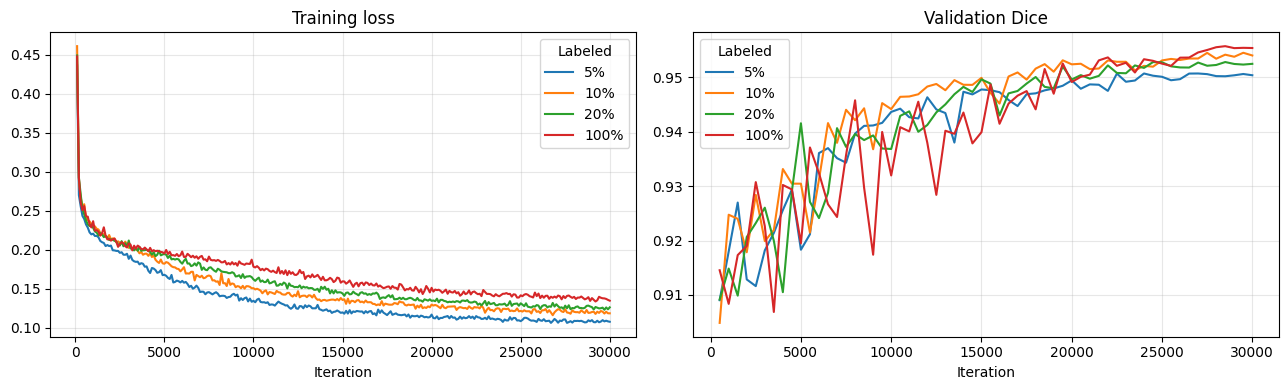

In [13]:
# ---- Results table (paper format: mean(std)) ----
df = pd.DataFrame(results)
table = pd.DataFrame({
    "Model": df["model"], "Labeled %": df["labeled_%"], "Seed": df["seed"],
    **{k.upper(): [f"{m:.2f}({s:.2f})" for m, s in zip(df[f"{k}_mean"], df[f"{k}_std"])]
       for k in ["dsc", "jaccard", "hd95", "asd"]}})
table.to_csv(RUN_ROOT / f"summary_{CFG.MODEL}.csv", index=False)
display(table)

# ---- Training curves ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ratio in CFG.LABELED_RATIOS:
    log = pd.read_csv(RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{CFG.SEEDS[0]}" / "log.csv")
    tr, va = log.dropna(subset=["loss"]), log.dropna(subset=["val_dice"])
    axes[0].plot(tr["iter"], tr["loss"], label=f"{ratio}%")
    axes[1].plot(va["iter"], va["val_dice"], label=f"{ratio}%")
axes[0].set(title="Training loss", xlabel="Iteration"); axes[1].set(title="Validation Dice", xlabel="Iteration")
for ax in axes:
    ax.legend(title="Labeled"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RUN_ROOT / f"curves_{CFG.MODEL}.png", dpi=150); plt.show()

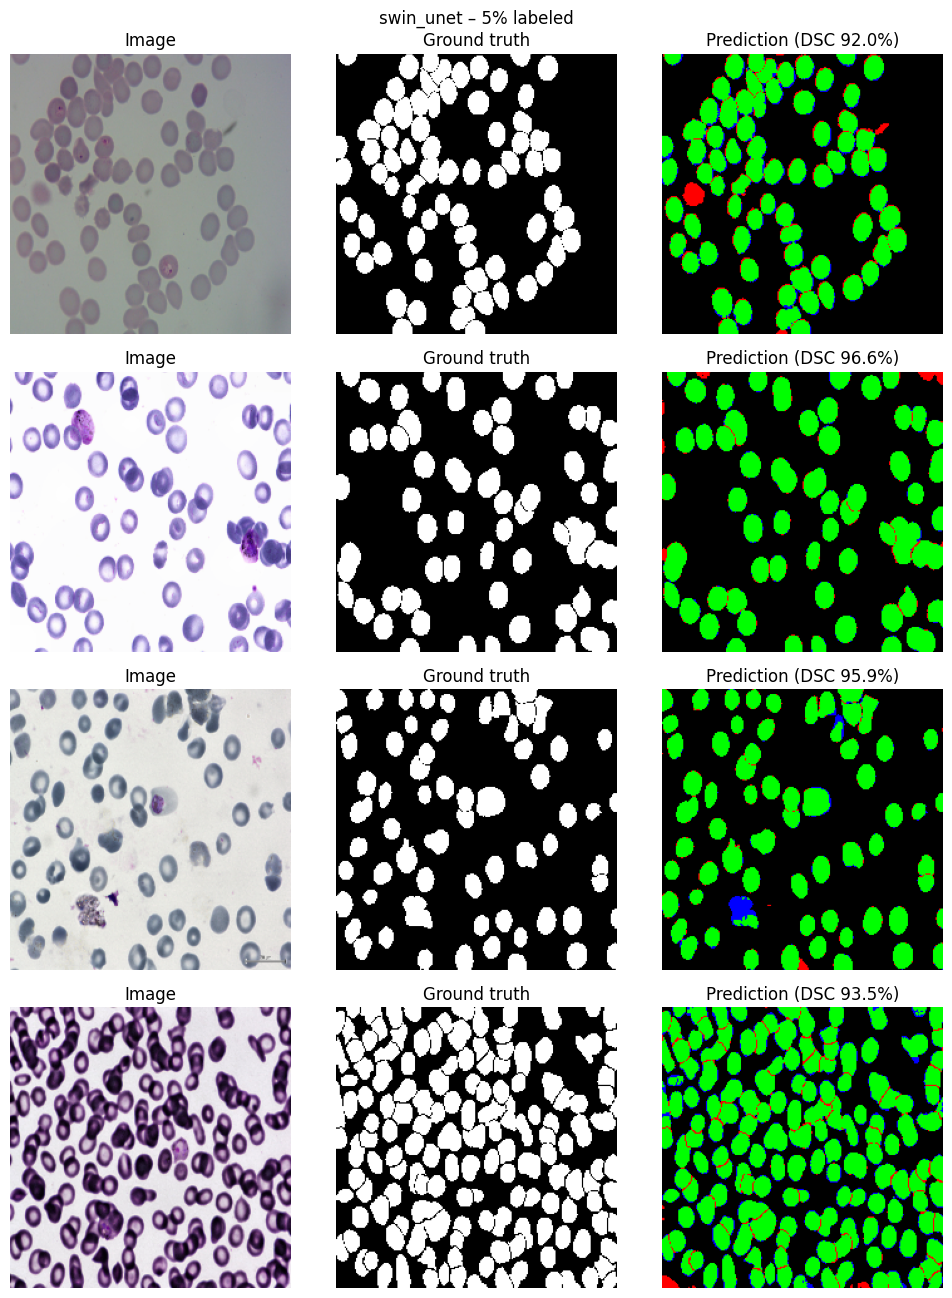

In [14]:
# ---- Test predictions: green = correct, red = false positive, blue = false negative ----
def show_predictions(ratio=None, n=4):
    ratio = ratio or CFG.LABELED_RATIOS[0]
    model = build_model(pretrained=False).to(DEVICE)
    ck = RUN_ROOT / f"{CFG.MODEL}_{ratio}p_s{CFG.SEEDS[0]}" / "best.pth"
    model.load_state_dict(torch.load(ck, map_location=DEVICE)["model"]); model.eval()
    ds = BloodCellDataset(SPLIT["test"][:n], build_eval_transform())
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.3 * n))
    for i in range(n):
        b = ds[i]
        with torch.no_grad():
            p = model(b["image"][None].to(DEVICE)).argmax(1)[0].cpu().numpy().astype(bool)
        g = b["mask"].numpy().astype(bool)
        img = b["image"].permute(1, 2, 0).numpy() * np.array(AUG.STD) + np.array(AUG.MEAN)
        img = np.clip(img, 0, 1)
        err = np.zeros((*g.shape, 3)); err[p & g] = (0, 1, 0); err[p & ~g] = (1, 0, 0); err[~p & g] = (0, 0, 1)
        d = binary_metrics(p, g)["dsc"] * 100
        for ax, im, t in zip(axes[i], [img, g, err], ["Image", "Ground truth", f"Prediction (DSC {d:.1f}%)"]):
            ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
    plt.suptitle(f"{CFG.MODEL} – {ratio}% labeled"); plt.tight_layout(); plt.show()


show_predictions()

In [15]:
# ---- Package results (without last.pth) -> download from the Output tab ----
zip_path = Path(CFG.WORK_DIR) / f"results_{CFG.MODEL}"
tmp = Path(CFG.WORK_DIR) / "_pack"
shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(RUN_ROOT, tmp, ignore=shutil.ignore_patterns("last.pth"))
shutil.make_archive(str(zip_path), "zip", tmp)
shutil.rmtree(tmp)
print("Created", zip_path.with_suffix(".zip"))

Created /kaggle/working/results_swin_unet.zip
